# Chapter 9: Categories vs Categories

Companion notebook for *Master Exploratory Data Analysis: A Hands-On Beginner's Guide with Python, Statistics & A/B Testing*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files are in the same folder as this notebook.

## 9.1 Counting Pairs of Labels

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.style.use('book.mplstyle')

customers = pd.read_csv('customers.csv', parse_dates=['signup_date'])
cancellations = pd.read_csv('cancellations.csv',
                            parse_dates=['cancel_date'])
tickets = pd.read_csv('support_tickets.csv',
                      parse_dates=['opened_date'])
customers[['customer_id', 'channel', 'plan', 'device']].head()

,customer_id,channel,plan,device
0,1001,Podcast,Basic,Desktop
1,1002,Email,Basic,Desktop
2,1003,Email,Standard,Mobile
3,1004,Search,Basic,Desktop
4,1005,Search,Basic,Mobile


In [2]:
customers['cancelled'] = customers['customer_id'].isin(
    cancellations['customer_id'])
customers['cancelled'].value_counts()

cancelled
True     2369
False    1841
Name: count, dtype: int64

### `pd.crosstab()`

In [3]:
plan_cancel = pd.crosstab(customers['plan'], customers['cancelled'])
plan_cancel

cancelled,False,True
plan,,
Basic,568,1319
Premium,509,303
Standard,764,747


### Totals with `margins=True`

In [4]:
pd.crosstab(customers['plan'], customers['cancelled'], margins=True)

cancelled,False,True,All
plan,,,
Basic,568,1319,1887
Premium,509,303,812
Standard,764,747,1511
All,1841,2369,4210


## 9.2 Row, Column and Overall Shares

### Row shares with `normalize='index'`

In [5]:
pd.crosstab(customers['plan'], customers['cancelled'],
            normalize='index').round(3)

cancelled,False,True
plan,,
Basic,0.301,0.699
Premium,0.627,0.373
Standard,0.506,0.494


### Column shares with `normalize='columns'`

In [6]:
pd.crosstab(customers['plan'], customers['cancelled'],
            normalize='columns').round(3)

cancelled,False,True
plan,,
Basic,0.309,0.557
Premium,0.276,0.128
Standard,0.415,0.315


### Overall shares with `normalize='all'`

In [7]:
pd.crosstab(customers['plan'], customers['cancelled'],
            normalize='all').round(3)

cancelled,False,True
plan,,
Basic,0.135,0.313
Premium,0.121,0.072
Standard,0.181,0.177


### Shares with totals

In [8]:
pd.crosstab(customers['plan'], customers['cancelled'],
            normalize='index', margins=True).round(3)

cancelled,False,True
plan,,
Basic,0.301,0.699
Premium,0.627,0.373
Standard,0.506,0.494
All,0.437,0.563


### Reading reasons by plan

In [9]:
cancel_plan = cancellations.merge(
    customers[['customer_id', 'plan', 'region']],
    on='customer_id', validate='one_to_one')
reason_plan = pd.crosstab(cancel_plan['reason'], cancel_plan['plan'])
reason_plan

plan,Basic,Premium,Standard
reason,,,
Delivery problems,176,55,125
Other,247,55,149
Taste,233,51,142
Too expensive,474,47,126
Too much coffee,189,95,205


In [10]:
pd.crosstab(cancel_plan['reason'], cancel_plan['plan'],
            normalize='columns').round(3)

plan,Basic,Premium,Standard
reason,,,
Delivery problems,0.133,0.182,0.167
Other,0.187,0.182,0.199
Taste,0.177,0.168,0.190
Too expensive,0.359,0.155,0.169
Too much coffee,0.143,0.314,0.274


In [11]:
pd.crosstab(cancel_plan['reason'], cancel_plan['plan'],
            normalize='index').round(3)

plan,Basic,Premium,Standard
reason,,,
Delivery problems,0.494,0.154,0.351
Other,0.548,0.122,0.330
Taste,0.547,0.120,0.333
Too expensive,0.733,0.073,0.195
Too much coffee,0.387,0.194,0.419


## 9.3 Charting Shares

### `df.plot.barh()`

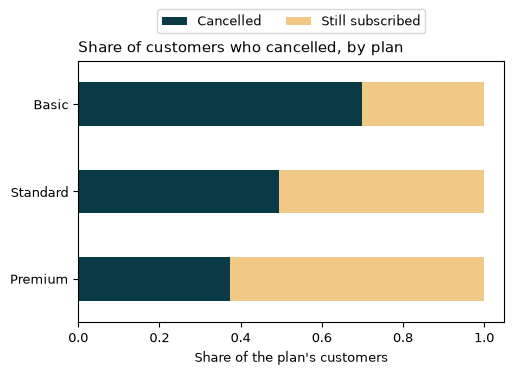

In [12]:
plan_order = ['Basic', 'Standard', 'Premium']
plan_shares = (pd.crosstab(customers['plan'], customers['cancelled'],
                           normalize='index')
               .loc[plan_order]
               .rename(columns={True: 'Cancelled',
                                False: 'Still subscribed'}))
plan_shares = plan_shares[['Cancelled', 'Still subscribed']]

ax = plan_shares.plot.barh(stacked=True,
                           color=['#0b3a47', '#f0c987'])
ax.invert_yaxis()
ax.set_title('Share of customers who cancelled, by plan')
ax.set_xlabel("Share of the plan's customers")
ax.set_ylabel('')
ax.legend(ncols=2, loc='lower center', bbox_to_anchor=(0.5, 1.08))
plt.show()

### Plan choice by channel

In [13]:
channel_plan = pd.crosstab(customers['channel'], customers['plan'],
                           normalize='index')[plan_order]
channel_plan.round(3)

plan,Basic,Standard,Premium
channel,,,
Email,0.324,0.436,0.240
Podcast,0.872,0.108,0.021
Referral,0.261,0.487,0.252
Search,0.324,0.410,0.266
Social,0.499,0.351,0.151


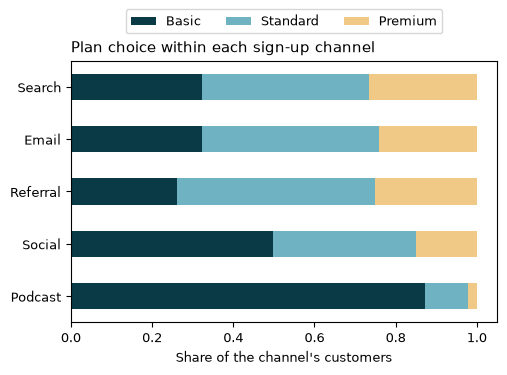

In [14]:
channel_order = ['Search', 'Email', 'Referral', 'Social', 'Podcast']

ax = channel_plan.loc[channel_order].plot.barh(
    stacked=True, color=['#0b3a47', '#6fb3c2', '#f0c987'])
ax.invert_yaxis()
ax.set_title('Plan choice within each sign-up channel')
ax.set_xlabel("Share of the channel's customers")
ax.set_ylabel('')
ax.legend(ncols=3, loc='lower center', bbox_to_anchor=(0.5, 1.08))
plt.show()

### Grouped bars

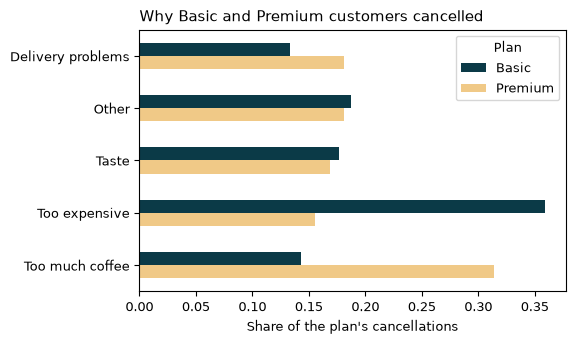

In [15]:
reason_shares = pd.crosstab(cancel_plan['reason'],
                            cancel_plan['plan'],
                            normalize='columns')
reason_shares = reason_shares[['Basic', 'Premium']]

ax = reason_shares.plot.barh(color=['#0b3a47', '#f0c987'])
ax.invert_yaxis()
ax.set_title('Why Basic and Premium customers cancelled')
ax.set_xlabel("Share of the plan's cancellations")
ax.set_ylabel('')
ax.legend(title='Plan')
plt.show()

## 9.4 One Number for a Link: Cramér's V

### `stats.contingency.association()`

In [16]:
plan_v = stats.contingency.association(plan_cancel)
print(f"Cramér's V, plan vs cancelled: {plan_v:.2f}")

Cramér's V, plan vs cancelled: 0.26


### What 0 and 1 look like

In [17]:
same_mix = pd.DataFrame({'Decaf': [30, 60], 'Regular': [70, 140]},
                        index=['Austin', 'Denver'])
all_or_none = pd.DataFrame({'Decaf': [100, 0], 'Regular': [0, 200]},
                           index=['Austin', 'Denver'])
print(f'Same mix: V = '
      f'{stats.contingency.association(same_mix):.2f}')
print(f'All or none: V = '
      f'{stats.contingency.association(all_or_none):.2f}')

Same mix: V = 0.00
All or none: V = 1.00


### Comparing links across the dataset

In [18]:
def cramers_v(df, col_a, col_b):
    counts = pd.crosstab(df[col_a], df[col_b])
    return stats.contingency.association(counts)

pairs = [('plan', 'cancelled'), ('channel', 'plan'),
         ('channel', 'cancelled'), ('region', 'plan'),
         ('device', 'plan')]
for col_a, col_b in pairs:
    v = cramers_v(customers, col_a, col_b)
    print(f'{col_a:>8} vs {col_b:<9}  V = {v:.2f}')

    plan vs cancelled  V = 0.26
 channel vs plan       V = 0.29
 channel vs cancelled  V = 0.16
  region vs plan       V = 0.03
  device vs plan       V = 0.01


In [19]:
reason_v = stats.contingency.association(reason_plan)
print(f"Cramér's V, reason vs plan: {reason_v:.2f}")

Cramér's V, reason vs plan: 0.18


### What V doesn't tell you

In [20]:
ticket_region = tickets.merge(customers[['customer_id', 'region']],
                              on='customer_id', validate='many_to_one')
topic_region = pd.crosstab(ticket_region['topic'],
                           ticket_region['region'])
topic_v = stats.contingency.association(topic_region)
print(f"Cramér's V, topic vs region: {topic_v:.2f}")
pd.crosstab(ticket_region['topic'], ticket_region['region'],
            normalize='columns').round(3)

Cramér's V, topic vs region: 0.13


region,Midwest,Northeast,South,West
topic,,,,
Billing,0.169,0.231,0.201,0.151
Change address,0.132,0.095,0.134,0.091
Late delivery,0.338,0.321,0.400,0.570
Other,0.142,0.145,0.122,0.073
Product quality,0.219,0.208,0.144,0.115
